# Quantum-Inspired Logistics Optimization Prototype

**Project:** Omni-Grid Renewable Energy Intelligence Platform  
**Model:** Quantum-Inspired Logistics Optimization v1.0  
**Prototype Type:** Predictive maintenance demand generation + vehicle routing + spare-parts logistics optimization  
**Author:** Kazi Abdul Mubin  

## Prototype objective

This notebook builds a detailed prototype for the **Quantum-Inspired Logistics Optimization** model. The aim is to convert inverter health and failure-risk data into logistics decisions:

1. Predict near-term failure risk from inverter telemetry.
2. Convert high-risk assets into maintenance logistics jobs.
3. Simulate the missing logistics attributes needed for routing, such as depot, coordinates, crew capacity, parts, time windows, and skills.
4. Build a baseline routing plan.
5. Improve the plan using a **quantum-inspired simulated annealing optimizer**.
6. Produce an optimized crew schedule, route visualisation, KPI comparison, and spare-parts reorder plan.

## Important dataset note

The provided file is named as a Quantum-Inspired Logistics Optimization dataset, but its columns are mostly inverter health, telemetry, degradation, and failure-risk fields. It does **not** directly contain logistics fields such as depot location, vehicle routes, delivery deadlines, vehicle capacity, or spare-part inventory.  

Therefore, this prototype uses the real columns to estimate **maintenance demand and urgency**, then creates transparent synthetic logistics fields for route optimization. This is appropriate for the prototype stage and can later be replaced with real depot, CMMS, ERP, and fleet-management data.

In [1]:
# ============================================================
# 1. Environment setup
# ============================================================

import os
import math
import random
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    roc_curve,
)
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 160)

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
# ================================================================
# Data paths (portable)
# ================================================================
# Run this notebook from its own module folder. Data lives in ./data.
# If the full synthetic dataset is not present, the sample file is used
# so the notebook still runs end to end for anyone who clones the repo.

DATA_DIR = Path.cwd() / "data"
DATASET_PATH = DATA_DIR / "synthetic_logistics_dataset.csv"
SAMPLE_PATH = DATA_DIR / "synthetic_logistics_sample.csv"
DICTIONARY_PATH = DATA_DIR / "synthetic_logistics_data_dictionary.csv"

if not DATASET_PATH.exists():
    print(f"Full dataset not found, using sample file: {SAMPLE_PATH.name}")
    DATASET_PATH = SAMPLE_PATH

DATA_PATH = DATASET_PATH
PROJECT_DIR = Path.cwd()
OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)
print("Dataset path:", DATA_PATH)


## 3. Load dataset and data dictionary

This section loads the provided telemetry/failure-risk dataset. The model will treat this as the operational source for identifying which assets need maintenance logistics attention.

In [ ]:
df = pd.read_csv(DATA_PATH, parse_dates=["date"])
df = df.sort_values(["inverter_id", "date"]).reset_index(drop=True)
dictionary_df = pd.read_csv(DICTIONARY_PATH) if DICTIONARY_PATH.exists() else pd.DataFrame()
sample_df = pd.read_csv(SAMPLE_PATH) if SAMPLE_PATH.exists() else pd.DataFrame()

print("Dataset shape:", df.shape)
print("Date range:", df["date"].min(), "to", df["date"].max())
print("Unique inverters:", df["inverter_id"].nunique())
print("Columns:", len(df.columns))

display(df.head())

if not dictionary_df.empty:
    print("\nData dictionary preview:")
    display(dictionary_df.head(10))

In [4]:
# ============================================================
# 4. Data quality overview
# ============================================================

quality_summary = pd.DataFrame({
    "column": df.columns,
    "dtype": df.dtypes.astype(str).values,
    "missing_count": df.isna().sum().values,
    "missing_pct": (df.isna().mean().values * 100).round(2),
    "unique_values": [df[c].nunique(dropna=True) for c in df.columns]
})

target_cols = ["failure_within_7d", "failure_within_30d", "failure_within_90d", "failed_today", "is_censored"]
print("Target / outcome distribution:")
for col in target_cols:
    if col in df.columns:
        print(f"\n{col}")
        print(df[col].value_counts(dropna=False))

print("\nData quality summary:")
display(quality_summary)

Target / outcome distribution:

failure_within_7d
failure_within_7d
0    32044
1      583
Name: count, dtype: int64

failure_within_30d
failure_within_30d
0    30365
1     2262
Name: count, dtype: int64

failure_within_90d
failure_within_90d
0    26139
1     6488
Name: count, dtype: int64

failed_today
failed_today
0    32555
1       72
Name: count, dtype: int64

is_censored
is_censored
1    17155
0    15472
Name: count, dtype: int64

Data quality summary:


,column,dtype,missing_count,missing_pct,unique_values
0,date,datetime64[ns],0,0.00,365
1,inverter_id,object,0,0.00,120
2,manufacturer,object,0,0.00,4
3,climate_zone,object,0,0.00,4
4,rated_capacity_kw,int64,0,0.00,5
5,installation_quality_score,float64,0,0.00,97
6,maintenance_quality_score,float64,0,0.00,96
7,age_months,float64,0,0.00,3575
8,ambient_temperature_c,float64,0,0.00,2875
9,humidity_pct,float64,0,0.00,7316


## 4. Advanced feature engineering

The raw dataset already contains useful rolling features, but for logistics optimization we need stronger signals that indicate operational urgency and service complexity.

The engineered features below help transform asset health into logistics demand:

- **Thermal stress:** internal temperature relative to ambient and rolling temperature means.
- **Electrical instability:** voltage ripple, harmonic distortion, and reactive power issues.
- **Restart/error intensity:** daily and rolling restart/error counts.
- **Degradation pressure:** capacitor degradation, efficiency loss, dust/soiling exposure.
- **Environmental interactions:** UV-temperature and soiling-humidity stress.
- **Temporal features:** month, weekday, year day, and week number.

In [5]:
# ============================================================
# 5. Advanced feature engineering
# ============================================================

df_fe = df.copy()

# Calendar features
df_fe["month"] = df_fe["date"].dt.month
df_fe["dayofweek"] = df_fe["date"].dt.dayofweek
df_fe["dayofyear"] = df_fe["date"].dt.dayofyear
df_fe["weekofyear"] = df_fe["date"].dt.isocalendar().week.astype(int)

# Thermal and performance gaps
df_fe["thermal_margin_c"] = df_fe["internal_temperature_c"] - df_fe["ambient_temperature_c"]
df_fe["efficiency_gap_30d"] = df_fe["efficiency_pct"] - df_fe["efficiency_30d_mean"]
df_fe["efficiency_gap_7d"] = df_fe["efficiency_pct"] - df_fe["efficiency_7d_mean"]
df_fe["temp_gap_30d"] = df_fe["internal_temperature_c"] - df_fe["temperature_30d_mean"]
df_fe["temp_gap_7d"] = df_fe["internal_temperature_c"] - df_fe["temperature_7d_mean"]

# Event intensity features
df_fe["restart_error_today"] = df_fe["restart_count_today"] + df_fe["error_code_count_today"]
df_fe["restart_error_7d"] = df_fe["restart_7d_sum"] + df_fe["errors_7d_sum"]
df_fe["thermal_overload_today"] = df_fe["thermal_cycling_count_today"] + 2 * df_fe["overload_events_today"]

# Composite stress scores
df_fe["degradation_pressure"] = (
    df_fe["capacitor_degradation_indicator"]
    + (100 - df_fe["efficiency_pct"])
    + df_fe["dust_soiling_index"]
)

df_fe["power_quality_risk"] = (
    df_fe["voltage_ripple"]
    + df_fe["current_harmonic_distortion_pct"]
    + (1 - df_fe["reactive_power_capability"]).clip(lower=0) * 10
)

df_fe["insulation_risk"] = 1 / df_fe["insulation_resistance_mohm"].clip(lower=1)
df_fe["uv_temp_interaction"] = df_fe["uv_exposure_index"] * df_fe["ambient_temperature_c"]
df_fe["soiling_humidity_interaction"] = df_fe["dust_soiling_index"] * df_fe["humidity_pct"]

# Extra rolling windows by inverter.
rolling_specs = [
    ("efficiency_pct", 14, "mean"),
    ("internal_temperature_c", 14, "mean"),
    ("restart_count_today", 14, "sum"),
    ("error_code_count_today", 14, "sum"),
    ("overload_events_today", 14, "sum"),
]

for col, window, agg in rolling_specs:
    new_col = f"{col}_{window}d_{agg}"
    if agg == "mean":
        df_fe[new_col] = df_fe.groupby("inverter_id")[col].transform(
            lambda s: s.rolling(window, min_periods=1).mean()
        )
    elif agg == "sum":
        df_fe[new_col] = df_fe.groupby("inverter_id")[col].transform(
            lambda s: s.rolling(window, min_periods=1).sum()
        )

print("Feature-engineered dataset shape:", df_fe.shape)
new_features = [c for c in df_fe.columns if c not in df.columns]
print("New engineered features:", len(new_features))
display(df_fe[["date", "inverter_id"] + new_features].head())

Feature-engineered dataset shape: (32627, 64)
New engineered features: 22


,date,inverter_id,month,dayofweek,dayofyear,weekofyear,thermal_margin_c,efficiency_gap_30d,efficiency_gap_7d,temp_gap_30d,temp_gap_7d,restart_error_today,restart_error_7d,thermal_overload_today,degradation_pressure,power_quality_risk,insulation_risk,uv_temp_interaction,soiling_humidity_interaction,efficiency_pct_14d_mean,internal_temperature_c_14d_mean,restart_count_today_14d_sum,error_code_count_today_14d_sum,overload_events_today_14d_sum
0,2025-01-01,INV-0001,1,2,1,1,8.94,0.0000,0.0000,0.000000,0.000000,0,0.0,3,2.789,8.062,0.012652,125.8351,11.69460,97.9300,28.510000,0.0,0.0,0.0
1,2025-01-02,INV-0001,1,3,2,1,13.16,-0.2350,-0.2350,4.065000,4.065000,0,0.0,0,3.269,8.078,0.012827,148.6284,14.35208,97.6950,32.575000,0.0,0.0,0.0
2,2025-01-03,INV-0001,1,4,3,1,10.53,0.2300,0.2300,-0.236667,-0.236667,0,0.0,0,2.584,9.045,0.012410,170.9172,15.06820,97.8100,32.456667,0.0,0.0,0.0
3,2025-01-04,INV-0001,1,5,4,1,13.67,-0.2475,-0.2475,1.982500,1.982500,0,0.0,6,3.208,7.911,0.013006,151.9387,4.18314,97.7275,33.117500,0.0,0.0,1.0
4,2025-01-05,INV-0001,1,6,5,1,13.24,0.5620,0.5620,2.698000,2.698000,0,0.0,0,2.305,9.081,0.012191,140.4300,12.29488,97.8680,33.792000,0.0,0.0,1.0


## 5. Failure-risk model

Quantum-inspired logistics optimization still needs a demand signal. In this prototype, the demand signal comes from a supervised model that predicts `failure_within_7d`.

The predicted failure probability becomes one of the key inputs for:

- job priority,
- time-window urgency,
- crew scheduling,
- spare-parts planning,
- route optimization objective penalties.

To avoid leakage, the model excludes future labels such as `failure_within_30d`, `failure_within_90d`, `failed_today`, `rul_days`, and `is_censored`.

In [6]:
# ============================================================
# 6. Temporal train-test split and model training
# ============================================================

TARGET = "failure_within_7d"
LEAKAGE_COLS = [
    "failure_within_7d",
    "failure_within_30d",
    "failure_within_90d",
    "failed_today",
    "rul_days",
    "is_censored",
]

feature_cols = [c for c in df_fe.columns if c not in LEAKAGE_COLS + ["date"]]
X = df_fe[feature_cols]
y = df_fe[TARGET]

# Temporal split: train on earlier months, test on later months.
cutoff_date = pd.Timestamp("2025-09-30")
train_mask = df_fe["date"] <= cutoff_date
test_mask = df_fe["date"] > cutoff_date

X_train, X_test = X.loc[train_mask], X.loc[test_mask]
y_train, y_test = y.loc[train_mask], y.loc[test_mask]

numeric_features = X_train.select_dtypes(include=["number", "bool"]).columns.tolist()
categorical_features = [c for c in X_train.columns if c not in numeric_features]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ]
)

failure_risk_model = Pipeline(
    steps=[
        ("preprocess", preprocessor),
        (
            "model",
            RandomForestClassifier(
                n_estimators=250,
                max_depth=12,
                min_samples_leaf=8,
                class_weight="balanced_subsample",
                random_state=RANDOM_STATE,
                n_jobs=-1,
            ),
        ),
    ]
)

failure_risk_model.fit(X_train, y_train)

print("Training period:", df_fe.loc[train_mask, "date"].min(), "to", df_fe.loc[train_mask, "date"].max())
print("Testing period:", df_fe.loc[test_mask, "date"].min(), "to", df_fe.loc[test_mask, "date"].max())
print("Training rows:", X_train.shape[0], "Testing rows:", X_test.shape[0])
print("Training positives:", int(y_train.sum()), "Testing positives:", int(y_test.sum()))

Training period: 2025-01-01 00:00:00 to 2025-09-30 00:00:00
Testing period: 2025-10-01 00:00:00 to 2025-12-31 00:00:00
Training rows: 27414 Testing rows: 5213
Training positives: 426 Testing positives: 157


In [7]:
# ============================================================
# 7. Model evaluation
# ============================================================

y_test_proba = failure_risk_model.predict_proba(X_test)[:, 1]

roc_auc = roc_auc_score(y_test, y_test_proba)
avg_precision = average_precision_score(y_test, y_test_proba)

precision, recall, thresholds = precision_recall_curve(y_test, y_test_proba)
f1_scores = 2 * precision * recall / (precision + recall + 1e-9)
best_idx = np.nanargmax(f1_scores[:-1])
best_threshold = float(thresholds[best_idx])

y_test_pred = (y_test_proba >= best_threshold).astype(int)

print(f"ROC-AUC: {roc_auc:.4f}")
print(f"Average precision: {avg_precision:.4f}")
print(f"Selected threshold: {best_threshold:.4f}")
print("\nClassification report:")
print(classification_report(y_test, y_test_pred, digits=4))

cm = confusion_matrix(y_test, y_test_pred)
print("Confusion matrix:")
print(cm)

ROC-AUC: 0.9981
Average precision: 0.9263
Selected threshold: 0.8057

Classification report:
              precision    recall  f1-score   support

           0     0.9986    0.9929    0.9957      5056
           1     0.8065    0.9554    0.8746       157

    accuracy                         0.9918      5213
   macro avg     0.9025    0.9741    0.9352      5213
weighted avg     0.9928    0.9918    0.9921      5213

Confusion matrix:
[[5020   36]
 [   7  150]]


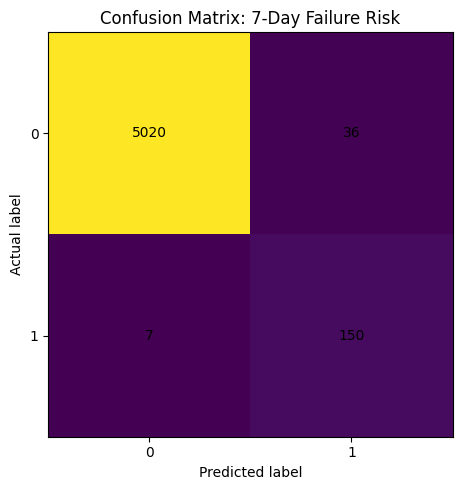

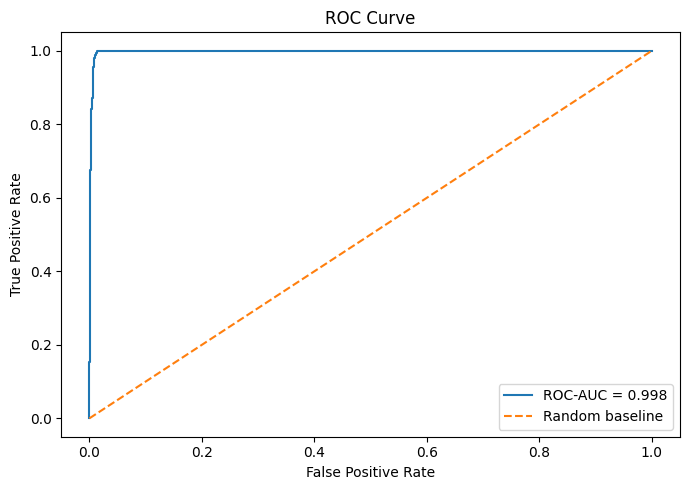

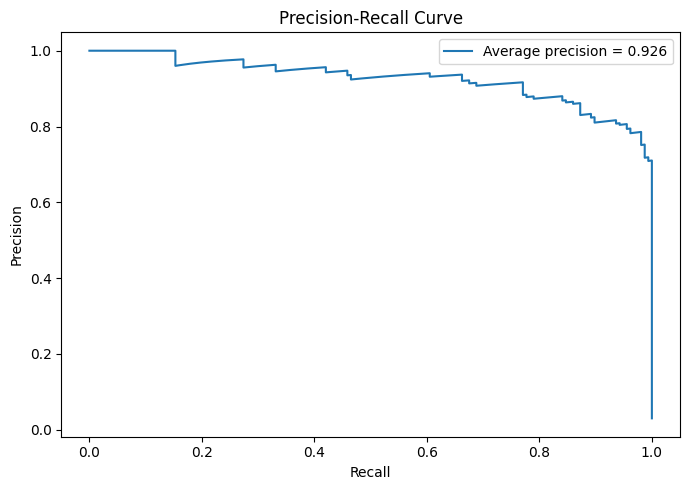

In [8]:
# ============================================================
# 8. Evaluation plots
# ============================================================

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm)
ax.set_title("Confusion Matrix: 7-Day Failure Risk")
ax.set_xlabel("Predicted label")
ax.set_ylabel("Actual label")
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, cm[i, j], ha="center", va="center")
plt.tight_layout()
plt.show()

fpr, tpr, _ = roc_curve(y_test, y_test_proba)
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
plt.plot(recall, precision, label=f"Average precision = {avg_precision:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.tight_layout()
plt.show()

Top model features:


,feature,importance
25,num__efficiency_30d_mean,0.124025
49,num__efficiency_pct_14d_mean,0.115124
24,num__efficiency_7d_mean,0.105767
52,num__error_code_count_today_14d_sum,0.064544
44,num__degradation_pressure,0.061288
18,num__capacitor_degradation_indicator,0.060502
12,num__efficiency_pct,0.054730
31,num__errors_7d_sum,0.049956
42,num__restart_error_7d,0.043965
51,num__restart_count_today_14d_sum,0.041836


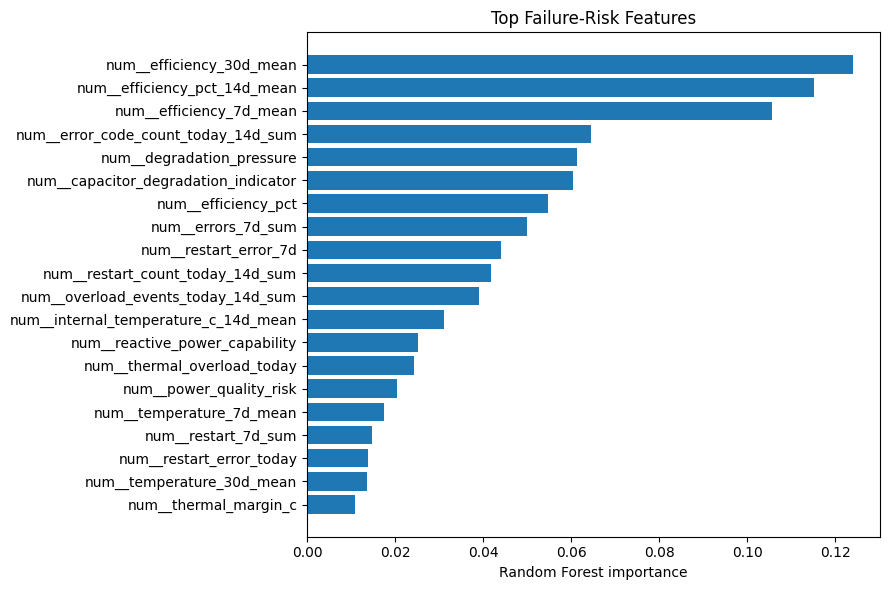

In [9]:
# ============================================================
# 9. Feature importance
# ============================================================

# Use built-in Random Forest importances after preprocessing.
model = failure_risk_model.named_steps["model"]
preprocess = failure_risk_model.named_steps["preprocess"]

try:
    transformed_feature_names = preprocess.get_feature_names_out()
except Exception:
    transformed_feature_names = [f"feature_{i}" for i in range(len(model.feature_importances_))]

importance_df = pd.DataFrame({
    "feature": transformed_feature_names,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

print("Top model features:")
display(importance_df.head(20))

plt.figure(figsize=(9, 6))
top_n = 20
plt.barh(importance_df.head(top_n)["feature"][::-1], importance_df.head(top_n)["importance"][::-1])
plt.xlabel("Random Forest importance")
plt.title("Top Failure-Risk Features")
plt.tight_layout()
plt.show()

## 6. Convert asset risk into logistics jobs

The next step is to convert model output into operational maintenance jobs. For each inverter, this prototype takes the latest available asset state and creates a logistics job profile containing:

- predicted 7-day failure risk,
- priority score,
- estimated part requirement,
- service duration,
- required crew skill,
- synthetic site coordinate,
- time window.

The synthetic logistics attributes are clearly separated from the real dataset-derived risk features so they can later be replaced by real ERP, CMMS, and fleet-management fields.

In [10]:
# ============================================================
# 10. Predict risk for all rows and create latest asset snapshot
# ============================================================

df_fe["predicted_failure_risk_7d"] = failure_risk_model.predict_proba(X)[:, 1]

latest_assets = (
    df_fe.sort_values("date")
    .groupby("inverter_id")
    .tail(1)
    .copy()
    .reset_index(drop=True)
)

print("Latest asset snapshot shape:", latest_assets.shape)
display(latest_assets[["date", "inverter_id", "manufacturer", "climate_zone", "predicted_failure_risk_7d", "failure_within_7d"]].head())

Latest asset snapshot shape: (120, 65)


,date,inverter_id,manufacturer,climate_zone,predicted_failure_risk_7d,failure_within_7d
0,2025-02-11,INV-0015,SMA,Humid-Subtropical,0.965842,1
1,2025-03-01,INV-0067,SMA,Coastal,0.987180,1
2,2025-03-04,INV-0030,SolarEdge,Coastal,0.984526,1
3,2025-03-20,INV-0072,SolarEdge,Temperate,0.993784,1
4,2025-03-21,INV-0065,SolarEdge,Temperate,0.993451,1


In [11]:
# ============================================================
# 11. Logistics enrichment functions
# ============================================================

def minmax(series):
    series = pd.Series(series)
    return (series - series.min()) / (series.max() - series.min() + 1e-9)

# Synthetic geographic centres by climate zone.
# Replace these with real site lat/lon when production data is available.
zone_centres = {
    "Coastal": (-33.86, 151.20),
    "Temperate": (-33.81, 151.10),
    "Hot-Dry": (-33.50, 150.78),
    "Humid-Subtropical": (-34.05, 150.95),
}

rng = np.random.default_rng(RANDOM_STATE)
site_lat = []
site_lon = []

for _, row in latest_assets.iterrows():
    centre = zone_centres.get(row["climate_zone"], (-33.85, 151.00))
    site_lat.append(centre[0] + rng.normal(0, 0.12))
    site_lon.append(centre[1] + rng.normal(0, 0.16))

latest_assets["site_lat"] = site_lat
latest_assets["site_lon"] = site_lon

# Asset criticality and health stress.
latest_assets["capacity_criticality"] = minmax(latest_assets["rated_capacity_kw"]) * (
    1 + (1 - latest_assets["maintenance_quality_score"])
)

latest_assets["health_stress_score"] = (
    0.25 * minmax(latest_assets["internal_temperature_c"])
    + 0.20 * minmax(latest_assets["voltage_ripple"])
    + 0.20 * minmax(latest_assets["current_harmonic_distortion_pct"])
    + 0.20 * minmax(latest_assets["capacitor_degradation_indicator"])
    + 0.15 * minmax(1 / latest_assets["insulation_resistance_mohm"].clip(lower=1))
)

latest_assets["priority_score"] = 100 * (
    0.45 * latest_assets["predicted_failure_risk_7d"]
    + 0.25 * latest_assets["health_stress_score"]
    + 0.20 * minmax(latest_assets["capacity_criticality"])
    + 0.10 * minmax(-latest_assets["efficiency_decline_7d"])
)
latest_assets["priority_score"] = latest_assets["priority_score"].clip(0, 100)

# Estimate part requirement from dominant fault pattern.
conditions = [
    latest_assets["internal_temperature_c"] > latest_assets["internal_temperature_c"].quantile(0.80),
    latest_assets["voltage_ripple"] > latest_assets["voltage_ripple"].quantile(0.80),
    latest_assets["capacitor_degradation_indicator"] > latest_assets["capacitor_degradation_indicator"].quantile(0.80),
    latest_assets["insulation_resistance_mohm"] < latest_assets["insulation_resistance_mohm"].quantile(0.20),
    (latest_assets["restart_7d_sum"] + latest_assets["errors_7d_sum"]) > 0,
]
choices = [
    "Cooling_Fan_Kit",
    "Power_Quality_Module",
    "Capacitor_Pack",
    "Insulation_Test_Kit",
    "Control_Board",
]
latest_assets["required_part_type"] = np.select(conditions, choices, default="General_Service_Kit")

part_weight = {
    "Cooling_Fan_Kit": 18,
    "Power_Quality_Module": 30,
    "Capacitor_Pack": 45,
    "Insulation_Test_Kit": 12,
    "Control_Board": 8,
    "General_Service_Kit": 10,
}
latest_assets["part_weight_kg"] = latest_assets["required_part_type"].map(part_weight)

# Service duration is synthetic but linked to priority and asset size.
latest_assets["service_duration_hr"] = np.where(
    latest_assets["priority_score"] >= 70,
    1.7,
    np.where(latest_assets["priority_score"] >= 45, 1.3, 0.9),
)
latest_assets["service_duration_hr"] += 0.0015 * latest_assets["rated_capacity_kw"]

# Time windows become tighter for higher-priority jobs.
latest_assets["tw_start_hr"] = np.select(
    [latest_assets["priority_score"] >= 70, latest_assets["priority_score"] >= 45],
    [8.0, 9.0],
    default=11.0,
)
latest_assets["tw_end_hr"] = np.select(
    [latest_assets["priority_score"] >= 70, latest_assets["priority_score"] >= 45],
    [12.0, 15.0],
    default=17.0,
)

latest_assets["skill_required"] = np.select(
    [
        latest_assets["required_part_type"].eq("Power_Quality_Module"),
        latest_assets["required_part_type"].eq("Insulation_Test_Kit"),
    ],
    ["Electrical", "Safety"],
    default="General",
)

print("Logistics-enriched asset table:")
display(
    latest_assets[[
        "inverter_id", "predicted_failure_risk_7d", "priority_score", "required_part_type",
        "part_weight_kg", "service_duration_hr", "tw_start_hr", "tw_end_hr", "skill_required",
        "site_lat", "site_lon"
    ]].sort_values("priority_score", ascending=False).head(10)
)

Logistics-enriched asset table:


,inverter_id,predicted_failure_risk_7d,priority_score,required_part_type,part_weight_kg,service_duration_hr,tw_start_hr,tw_end_hr,skill_required,site_lat,site_lon
18,INV-0006,0.982140,89.649411,Cooling_Fan_Kit,18,2.075,8.0,12.0,General,-33.873674,151.065575
37,INV-0059,0.994827,87.790907,Power_Quality_Module,30,2.075,8.0,12.0,Electrical,-33.482909,150.890478
73,INV-0086,0.900881,87.120369,Power_Quality_Module,30,2.075,8.0,12.0,Electrical,-33.883452,151.077473
40,INV-0037,0.973094,85.764052,Power_Quality_Module,30,2.075,8.0,12.0,Electrical,-33.995187,150.844092
26,INV-0012,0.998275,85.572616,Cooling_Fan_Kit,18,2.075,8.0,12.0,General,-33.674859,150.728853
24,INV-0013,0.998026,84.440292,Control_Board,8,2.075,8.0,12.0,General,-33.968530,150.960813
61,INV-0031,0.969163,84.057451,Capacitor_Pack,45,2.075,8.0,12.0,General,-33.833600,151.417470
8,INV-0078,0.996586,83.616244,Capacitor_Pack,45,2.075,8.0,12.0,General,-34.005750,150.796579
67,INV-0029,0.928192,82.676143,Capacitor_Pack,45,2.075,8.0,12.0,General,-33.676497,150.617507
5,INV-0096,0.995647,80.295349,Cooling_Fan_Kit,18,1.925,8.0,12.0,General,-33.394472,150.904447


In [12]:
# ============================================================
# 12. Select jobs for the optimization horizon
# ============================================================

# For a fast prototype run, optimize the top 20 jobs.
# Increase this to 50-100 for a larger experiment, but runtime will increase.
N_JOBS = 20

jobs = (
    latest_assets.sort_values("priority_score", ascending=False)
    .head(N_JOBS)
    .copy()
    .reset_index(drop=True)
)
jobs["job_id"] = [f"JOB-{i+1:03d}" for i in range(len(jobs))]

print("Selected jobs:", len(jobs))
display(
    jobs[[
        "job_id", "inverter_id", "priority_score", "predicted_failure_risk_7d",
        "required_part_type", "part_weight_kg", "service_duration_hr", "tw_start_hr", "tw_end_hr", "skill_required"
    ]]
)

jobs.to_csv(OUTPUT_DIR / "selected_logistics_jobs.csv", index=False)

Selected jobs: 20


,job_id,inverter_id,priority_score,predicted_failure_risk_7d,required_part_type,part_weight_kg,service_duration_hr,tw_start_hr,tw_end_hr,skill_required
0,JOB-001,INV-0006,89.649411,0.982140,Cooling_Fan_Kit,18,2.075,8.0,12.0,General
1,JOB-002,INV-0059,87.790907,0.994827,Power_Quality_Module,30,2.075,8.0,12.0,Electrical
2,JOB-003,INV-0086,87.120369,0.900881,Power_Quality_Module,30,2.075,8.0,12.0,Electrical
3,JOB-004,INV-0037,85.764052,0.973094,Power_Quality_Module,30,2.075,8.0,12.0,Electrical
4,JOB-005,INV-0012,85.572616,0.998275,Cooling_Fan_Kit,18,2.075,8.0,12.0,General
5,JOB-006,INV-0013,84.440292,0.998026,Control_Board,8,2.075,8.0,12.0,General
6,JOB-007,INV-0031,84.057451,0.969163,Capacitor_Pack,45,2.075,8.0,12.0,General
7,JOB-008,INV-0078,83.616244,0.996586,Capacitor_Pack,45,2.075,8.0,12.0,General
8,JOB-009,INV-0029,82.676143,0.928192,Capacitor_Pack,45,2.075,8.0,12.0,General
9,JOB-010,INV-0096,80.295349,0.995647,Cooling_Fan_Kit,18,1.925,8.0,12.0,General


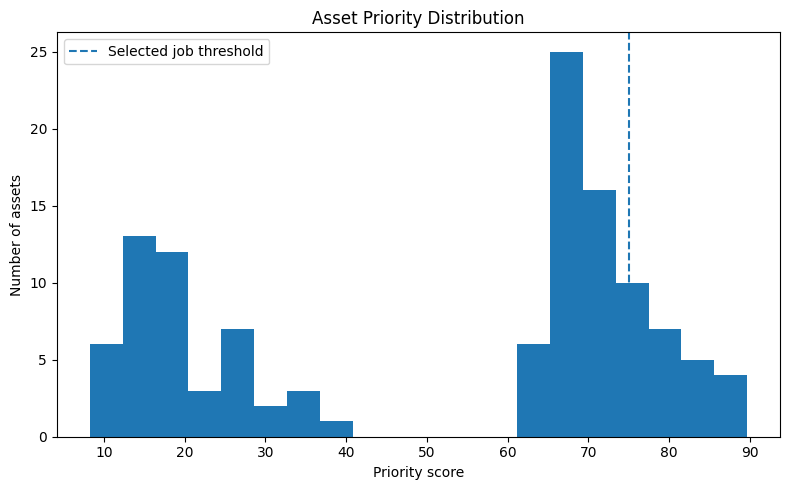

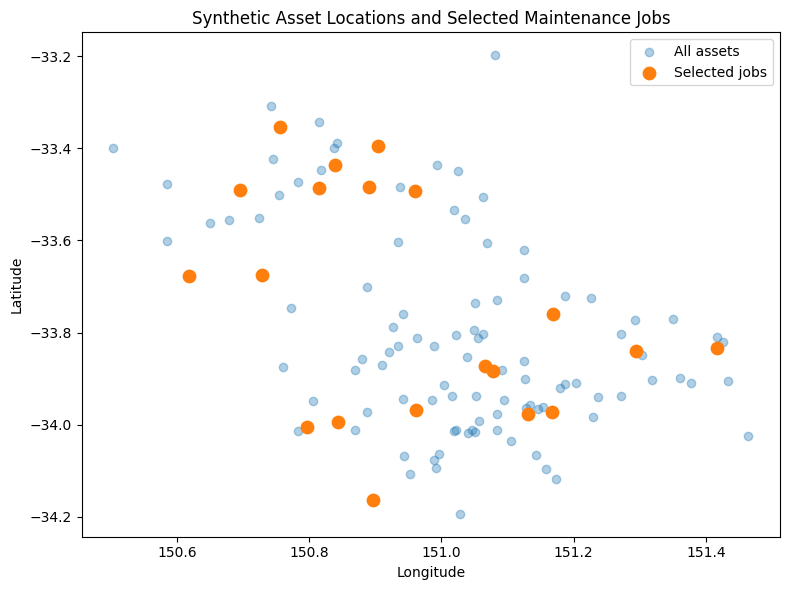

In [13]:
# ============================================================
# 13. Job priority and location visualisation
# ============================================================

plt.figure(figsize=(8, 5))
plt.hist(latest_assets["priority_score"], bins=20)
plt.axvline(jobs["priority_score"].min(), linestyle="--", label="Selected job threshold")
plt.xlabel("Priority score")
plt.ylabel("Number of assets")
plt.title("Asset Priority Distribution")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
plt.scatter(latest_assets["site_lon"], latest_assets["site_lat"], alpha=0.35, label="All assets")
plt.scatter(jobs["site_lon"], jobs["site_lat"], s=80, label="Selected jobs")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Synthetic Asset Locations and Selected Maintenance Jobs")
plt.legend()
plt.tight_layout()
plt.show()

## 7. Quantum-inspired optimization setup

A real quantum implementation would map the routing and assignment decision into binary variables and solve through a QAOA or annealing solver.

A simplified QUBO-style representation is:

\[
\min_x \sum_{i,j,k} d_{ij}x_{i,j,k} + \lambda_1\text{CapacityPenalty} + \lambda_2\text{TimeWindowPenalty} + \lambda_3\text{SkillPenalty} + \lambda_4\text{RiskDelayPenalty}
\]

where:

- \(x\) represents route assignment and sequence decisions,
- \(d_{ij}\) is travel distance between jobs,
- capacity penalty discourages overloaded vehicles,
- time-window penalty discourages late arrivals,
- skill penalty blocks assigning jobs to unsuitable crews,
- risk-delay penalty pushes high-risk assets earlier in the route.

Because Qiskit, D-Wave, and other quantum solvers may not be installed in the prototype environment, this notebook implements a **simulated annealing solver**. Simulated annealing is a quantum-inspired / annealing-style metaheuristic that can solve combinatorial routing problems without requiring quantum hardware.

In [14]:
# ============================================================
# 14. Depots, vehicles, and distance matrix
# ============================================================

vehicles = pd.DataFrame({
    "vehicle_id": ["CREW-1", "CREW-2", "CREW-3", "CREW-4", "CREW-5"],
    "depot_id": ["DEPOT_NORTH", "DEPOT_NORTH", "DEPOT_WEST", "DEPOT_WEST", "DEPOT_SOUTH"],
    "capacity_kg": [180, 180, 220, 220, 160],
    "shift_start_hr": [8, 8, 8, 8, 8],
    "shift_end_hr": [18, 18, 18, 18, 18],
    "skill_set": ["General,Electrical", "General", "General,Electrical", "General,Safety", "General,Safety"],
})

depots = {
    "DEPOT_NORTH": (-33.78, 151.12),
    "DEPOT_WEST": (-33.82, 150.99),
    "DEPOT_SOUTH": (-34.03, 150.90),
}

def haversine(lat1, lon1, lat2, lon2):
    """Distance in km between two latitude/longitude points."""
    radius_km = 6371.0
    phi1, phi2 = math.radians(lat1), math.radians(lat2)
    dphi = math.radians(lat2 - lat1)
    dlambda = math.radians(lon2 - lon1)
    a = math.sin(dphi / 2) ** 2 + math.cos(phi1) * math.cos(phi2) * math.sin(dlambda / 2) ** 2
    return 2 * radius_km * math.asin(math.sqrt(a))

coords = jobs[["site_lat", "site_lon"]].to_numpy()

# Job-to-job distance matrix.
D = np.zeros((len(jobs), len(jobs)))
for i in range(len(jobs)):
    for j in range(len(jobs)):
        D[i, j] = haversine(coords[i, 0], coords[i, 1], coords[j, 0], coords[j, 1])

def dist_depot_job(depot_id, job_index):
    depot_lat, depot_lon = depots[depot_id]
    return haversine(depot_lat, depot_lon, coords[job_index, 0], coords[job_index, 1])

print("Vehicles:")
display(vehicles)
print("Distance matrix shape:", D.shape)

Vehicles:


,vehicle_id,depot_id,capacity_kg,shift_start_hr,shift_end_hr,skill_set
0,CREW-1,DEPOT_NORTH,180,8,18,"General,Electrical"
1,CREW-2,DEPOT_NORTH,180,8,18,General
2,CREW-3,DEPOT_WEST,220,8,18,"General,Electrical"
3,CREW-4,DEPOT_WEST,220,8,18,"General,Safety"
4,CREW-5,DEPOT_SOUTH,160,8,18,"General,Safety"


Distance matrix shape: (20, 20)


In [15]:
# ============================================================
# 15. Baseline route constructor
# ============================================================

def build_baseline_routes(jobs, vehicles):
    """
    Greedy baseline:
    1. Sort jobs by priority.
    2. Assign each job to a compatible crew with the lowest current load and low depot distance.
    3. Order jobs within each vehicle route using nearest neighbour.
    """
    routes = [[] for _ in range(len(vehicles))]
    route_loads = [0.0 for _ in range(len(vehicles))]

    for _, job in jobs.sort_values("priority_score", ascending=False).iterrows():
        job_index = int(job.name)
        candidates = []
        for k, vehicle in vehicles.iterrows():
            skill_ok = (job["skill_required"] in vehicle["skill_set"]) or (job["skill_required"] == "General")
            if not skill_ok:
                continue
            capacity_penalty = max(0, route_loads[k] + job["part_weight_kg"] - vehicle["capacity_kg"]) * 100
            depot_distance = dist_depot_job(vehicle["depot_id"], job_index)
            candidates.append((route_loads[k] + capacity_penalty + depot_distance, k))

        selected_vehicle = min(candidates)[1]
        routes[selected_vehicle].append(job_index)
        route_loads[selected_vehicle] += float(job["part_weight_kg"])

    # Nearest-neighbour order inside each route.
    for k, route in enumerate(routes):
        ordered_route = []
        remaining = route.copy()
        current_job = None
        depot_id = vehicles.loc[k, "depot_id"]

        while remaining:
            if current_job is None:
                next_job = min(remaining, key=lambda j: dist_depot_job(depot_id, j))
            else:
                next_job = min(remaining, key=lambda j: D[current_job, j])
            ordered_route.append(next_job)
            remaining.remove(next_job)
            current_job = next_job

        routes[k] = ordered_route

    return routes

baseline_routes = build_baseline_routes(jobs, vehicles)

print("Baseline route job counts:")
for k, route in enumerate(baseline_routes):
    print(vehicles.loc[k, "vehicle_id"], "->", len(route), "jobs")

Baseline route job counts:
CREW-1 -> 3 jobs
CREW-2 -> 4 jobs
CREW-3 -> 5 jobs
CREW-4 -> 4 jobs
CREW-5 -> 4 jobs


In [16]:
# ============================================================
# 16. Objective function
# ============================================================

SPEED_KMPH = 55
COST_PER_KM = 1.25
CREW_COST_PER_HR = 85
LATE_PENALTY_PER_HR = 1200
OVERTIME_PENALTY_PER_HR = 900
CAPACITY_PENALTY_PER_KG = 500
SKILL_PENALTY = 500000
RISK_DELAY_WEIGHT = 30


def evaluate_routes(routes, return_schedule=False):
    """
    Evaluate route quality using a multi-objective cost function.

    Cost components:
    - travel distance cost
    - crew travel and service labour cost
    - time-window lateness penalty
    - overtime penalty
    - vehicle capacity penalty
    - crew skill mismatch penalty
    - risk delay penalty to prioritize high-risk assets earlier
    """
    total_distance = 0.0
    total_travel_hr = 0.0
    total_service_hr = 0.0
    total_lateness_hr = 0.0
    total_overtime_hr = 0.0
    capacity_violation_kg = 0.0
    skill_violations = 0
    schedule_rows = []

    for k, route in enumerate(routes):
        vehicle = vehicles.loc[k]
        current_time = float(vehicle["shift_start_hr"])
        route_load = float(jobs.loc[route, "part_weight_kg"].sum()) if route else 0.0
        capacity_violation_kg += max(0, route_load - float(vehicle["capacity_kg"]))

        previous_job = None
        route_distance = 0.0

        for position, job_index in enumerate(route):
            job = jobs.loc[job_index]

            if previous_job is None:
                distance_km = dist_depot_job(vehicle["depot_id"], job_index)
            else:
                distance_km = D[previous_job, job_index]

            travel_hr = distance_km / SPEED_KMPH
            current_time += travel_hr
            arrival_hr = current_time

            # Wait if the crew arrives before the job window opens.
            wait_hr = max(0, float(job["tw_start_hr"]) - arrival_hr)
            current_time += wait_hr

            lateness_hr = max(0, current_time - float(job["tw_end_hr"]))
            total_lateness_hr += lateness_hr

            skill_ok = (job["skill_required"] in vehicle["skill_set"]) or (job["skill_required"] == "General")
            if not skill_ok:
                skill_violations += 1

            service_start_hr = current_time
            service_finish_hr = service_start_hr + float(job["service_duration_hr"])

            schedule_rows.append({
                "vehicle_id": vehicle["vehicle_id"],
                "depot_id": vehicle["depot_id"],
                "sequence": position + 1,
                "job_id": job["job_id"],
                "inverter_id": job["inverter_id"],
                "priority_score": job["priority_score"],
                "predicted_failure_risk_7d": job["predicted_failure_risk_7d"],
                "required_part_type": job["required_part_type"],
                "skill_required": job["skill_required"],
                "arrival_hr": arrival_hr,
                "service_start_hr": service_start_hr,
                "service_finish_hr": service_finish_hr,
                "lateness_hr": lateness_hr,
                "distance_from_previous_km": distance_km,
            })

            current_time = service_finish_hr
            total_travel_hr += travel_hr
            total_service_hr += float(job["service_duration_hr"])
            route_distance += distance_km
            previous_job = job_index

        # Return to depot.
        if previous_job is not None:
            return_distance = dist_depot_job(vehicle["depot_id"], previous_job)
            route_distance += return_distance
            return_travel_hr = return_distance / SPEED_KMPH
            total_travel_hr += return_travel_hr
            current_time += return_travel_hr

        total_distance += route_distance
        total_overtime_hr += max(0, current_time - float(vehicle["shift_end_hr"]))

    schedule_df = pd.DataFrame(schedule_rows)

    objective = (
        COST_PER_KM * total_distance
        + CREW_COST_PER_HR * (total_travel_hr + total_service_hr)
        + LATE_PENALTY_PER_HR * total_lateness_hr
        + OVERTIME_PENALTY_PER_HR * total_overtime_hr
        + CAPACITY_PENALTY_PER_KG * capacity_violation_kg
        + SKILL_PENALTY * skill_violations
    )

    if not schedule_df.empty:
        risk_delay = float(((schedule_df["service_start_hr"] - 8).clip(lower=0) * schedule_df["priority_score"]).sum())
    else:
        risk_delay = 0.0
    objective += RISK_DELAY_WEIGHT * risk_delay

    high_priority = schedule_df[schedule_df["priority_score"] >= 70].copy() if not schedule_df.empty else pd.DataFrame()
    high_priority_on_time_rate = 0.0
    if len(high_priority) > 0:
        high_priority_on_time_rate = float((high_priority["lateness_hr"] == 0).mean())

    kpis = {
        "objective": objective,
        "total_distance_km": total_distance,
        "total_travel_hr": total_travel_hr,
        "total_service_hr": total_service_hr,
        "total_lateness_hr": total_lateness_hr,
        "total_overtime_hr": total_overtime_hr,
        "capacity_violation_kg": capacity_violation_kg,
        "skill_violations": skill_violations,
        "high_priority_on_time_rate": high_priority_on_time_rate,
        "num_jobs": len(jobs),
    }

    if return_schedule:
        return kpis, schedule_df
    return kpis

baseline_kpis, baseline_schedule = evaluate_routes(baseline_routes, return_schedule=True)
print("Baseline KPIs:")
display(pd.DataFrame([baseline_kpis]).T.rename(columns={0: "baseline"}))
display(baseline_schedule.head())

Baseline KPIs:


,baseline
objective,250388.716895
total_distance_km,731.185529
total_travel_hr,13.294282
total_service_hr,40.225000
total_lateness_hr,29.338883
total_overtime_hr,5.414865
capacity_violation_kg,0.000000
skill_violations,0.000000
high_priority_on_time_rate,0.500000
num_jobs,20.000000


,vehicle_id,depot_id,sequence,job_id,inverter_id,priority_score,predicted_failure_risk_7d,required_part_type,skill_required,arrival_hr,service_start_hr,service_finish_hr,lateness_hr,distance_from_previous_km
0,CREW-1,DEPOT_NORTH,1,JOB-011,INV-0005,79.559376,0.994164,Power_Quality_Module,Electrical,8.091220,8.091220,10.016220,0.000000,5.017125
1,CREW-1,DEPOT_NORTH,2,JOB-004,INV-0037,85.764052,0.973094,Power_Quality_Module,Electrical,10.739038,10.739038,12.814038,0.000000,39.754938
2,CREW-1,DEPOT_NORTH,3,JOB-002,INV-0059,87.790907,0.994827,Power_Quality_Module,Electrical,13.852655,13.852655,15.927655,1.852655,57.123972
3,CREW-2,DEPOT_NORTH,1,JOB-007,INV-0031,84.057451,0.969163,Capacitor_Pack,General,8.511331,8.511331,10.586331,0.000000,28.123217
4,CREW-2,DEPOT_NORTH,2,JOB-013,INV-0089,78.450987,0.947025,Cooling_Fan_Kit,General,11.619960,11.619960,13.694960,0.000000,56.849584


In [17]:
# ============================================================
# 17. Quantum-inspired simulated annealing optimizer
# ============================================================

rng_py = random.Random(RANDOM_STATE)

def clone_routes(routes):
    return [route.copy() for route in routes]


def make_neighbor(routes):
    """
    Create a neighbouring solution using one of three moves:
    - swap two jobs
    - relocate one job to another route
    - reverse part of a route
    """
    new_routes = clone_routes(routes)
    non_empty_routes = [i for i, route in enumerate(new_routes) if len(route) > 0]

    if not non_empty_routes:
        return new_routes

    move_type = rng_py.choice(["swap", "relocate", "reverse"])

    if move_type == "swap" and len(non_empty_routes) >= 1:
        if len(non_empty_routes) >= 2:
            route_a, route_b = rng_py.sample(non_empty_routes, 2)
        else:
            route_a = route_b = non_empty_routes[0]
        idx_a = rng_py.randrange(len(new_routes[route_a]))
        idx_b = rng_py.randrange(len(new_routes[route_b]))
        new_routes[route_a][idx_a], new_routes[route_b][idx_b] = new_routes[route_b][idx_b], new_routes[route_a][idx_a]

    elif move_type == "relocate":
        route_a = rng_py.choice(non_empty_routes)
        route_b = rng_py.randrange(len(new_routes))
        idx_a = rng_py.randrange(len(new_routes[route_a]))
        job = new_routes[route_a].pop(idx_a)
        idx_b = rng_py.randrange(len(new_routes[route_b]) + 1)
        new_routes[route_b].insert(idx_b, job)

    elif move_type == "reverse":
        reversible_routes = [i for i, route in enumerate(new_routes) if len(route) >= 2]
        if reversible_routes:
            route_a = rng_py.choice(reversible_routes)
            i, j = sorted(rng_py.sample(range(len(new_routes[route_a])), 2))
            new_routes[route_a][i:j+1] = reversed(new_routes[route_a][i:j+1])

    return new_routes


def simulated_annealing(initial_routes, iterations=3000, start_temp=5000, cooling=0.996):
    current_routes = clone_routes(initial_routes)
    current_kpis = evaluate_routes(current_routes)
    current_obj = current_kpis["objective"]

    best_routes = clone_routes(current_routes)
    best_kpis = current_kpis
    best_obj = current_obj

    history = []
    temperature = start_temp

    for iteration in range(1, iterations + 1):
        candidate_routes = make_neighbor(current_routes)
        candidate_kpis = evaluate_routes(candidate_routes)
        candidate_obj = candidate_kpis["objective"]

        delta = candidate_obj - current_obj
        accept = delta < 0 or rng_py.random() < math.exp(-delta / max(temperature, 1e-9))

        if accept:
            current_routes = candidate_routes
            current_kpis = candidate_kpis
            current_obj = candidate_obj

        if current_obj < best_obj:
            best_routes = clone_routes(current_routes)
            best_kpis = current_kpis
            best_obj = current_obj

        history.append({
            "iteration": iteration,
            "temperature": temperature,
            "current_objective": current_obj,
            "best_objective": best_obj,
        })

        temperature *= cooling

    return best_routes, best_kpis, pd.DataFrame(history)

optimized_routes, optimized_kpis, annealing_history = simulated_annealing(baseline_routes)
optimized_kpis, optimized_schedule = evaluate_routes(optimized_routes, return_schedule=True)

print("Optimization complete.")
print("Baseline objective:", round(baseline_kpis["objective"], 2))
print("Optimized objective:", round(optimized_kpis["objective"], 2))
print("Objective improvement (%):", round(100 * (baseline_kpis["objective"] - optimized_kpis["objective"]) / baseline_kpis["objective"], 2))

Optimization complete.
Baseline objective: 250388.72
Optimized objective: 216296.62
Objective improvement (%): 13.62


,scenario,objective,total_distance_km,total_travel_hr,total_service_hr,total_lateness_hr,total_overtime_hr,capacity_violation_kg,skill_violations,high_priority_on_time_rate
0,Baseline,250388.716895,731.185529,13.294282,40.225,29.338883,5.414865,0.0,0,0.5
1,Quantum-inspired SA Optimized,216296.623304,569.442197,10.353494,40.225,21.149604,0.855739,0.0,0,0.5


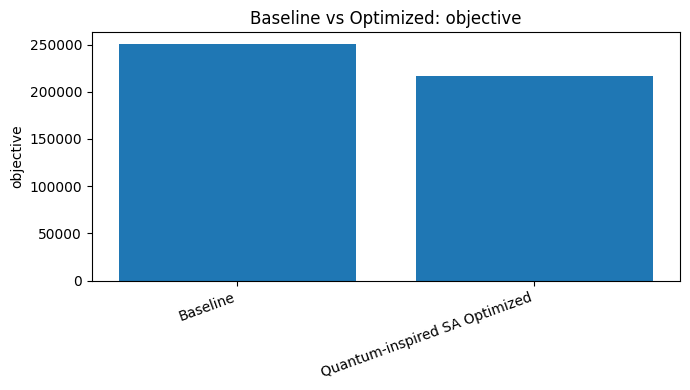

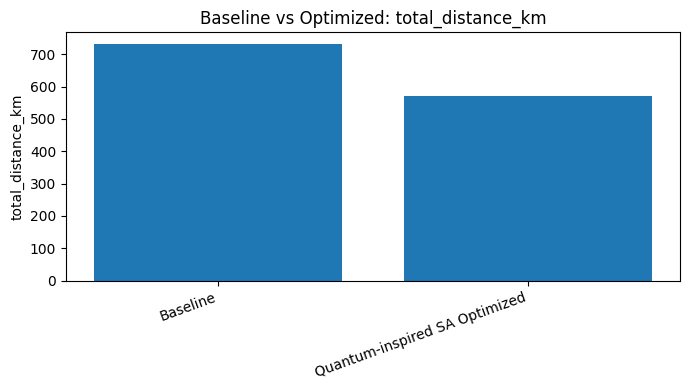

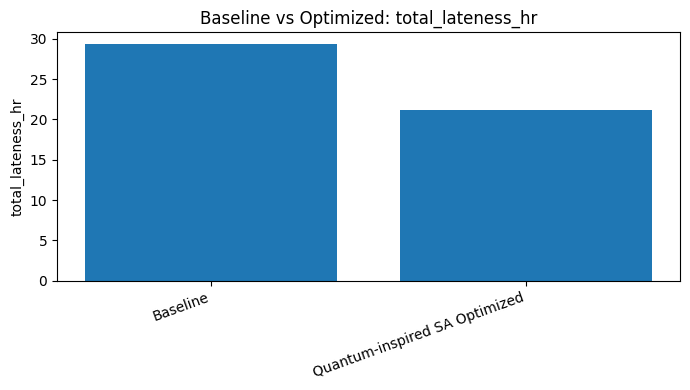

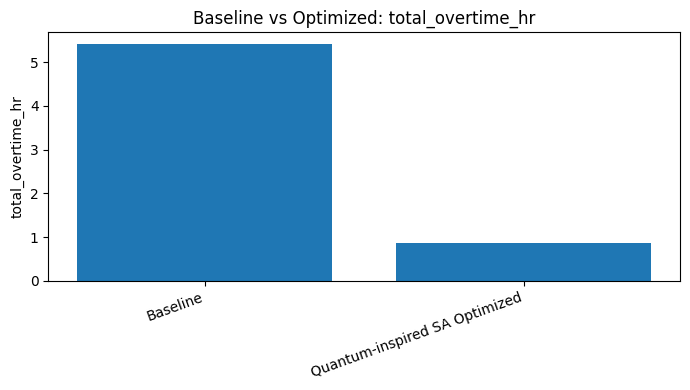

In [18]:
# ============================================================
# 18. KPI comparison
# ============================================================

comparison_df = pd.DataFrame([
    {"scenario": "Baseline", **baseline_kpis},
    {"scenario": "Quantum-inspired SA Optimized", **optimized_kpis},
])

metric_cols = [
    "objective",
    "total_distance_km",
    "total_travel_hr",
    "total_service_hr",
    "total_lateness_hr",
    "total_overtime_hr",
    "capacity_violation_kg",
    "skill_violations",
    "high_priority_on_time_rate",
]

display(comparison_df[["scenario"] + metric_cols])

for metric in ["objective", "total_distance_km", "total_lateness_hr", "total_overtime_hr"]:
    plt.figure(figsize=(7, 4))
    plt.bar(comparison_df["scenario"], comparison_df[metric])
    plt.ylabel(metric)
    plt.title(f"Baseline vs Optimized: {metric}")
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.show()

comparison_df.to_csv(OUTPUT_DIR / "routing_kpi_comparison.csv", index=False)

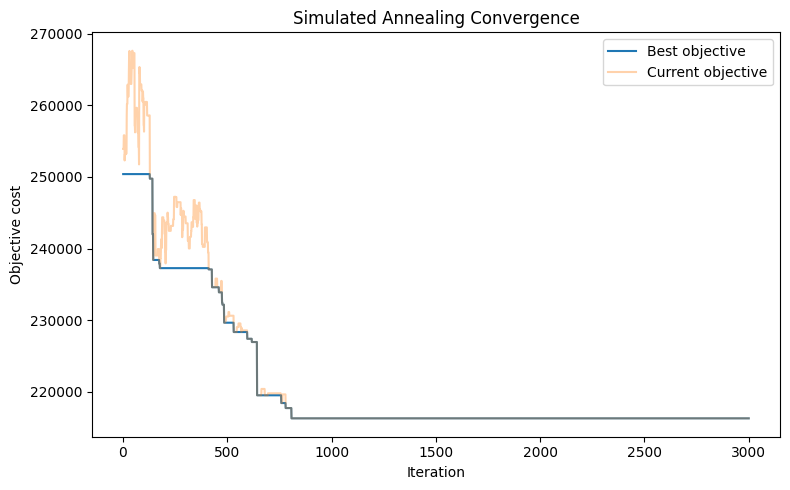

In [19]:
# ============================================================
# 19. Annealing convergence plot
# ============================================================

plt.figure(figsize=(8, 5))
plt.plot(annealing_history["iteration"], annealing_history["best_objective"], label="Best objective")
plt.plot(annealing_history["iteration"], annealing_history["current_objective"], alpha=0.35, label="Current objective")
plt.xlabel("Iteration")
plt.ylabel("Objective cost")
plt.title("Simulated Annealing Convergence")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "qilo_simulated_annealing_convergence.png", dpi=150, bbox_inches="tight")
plt.show()

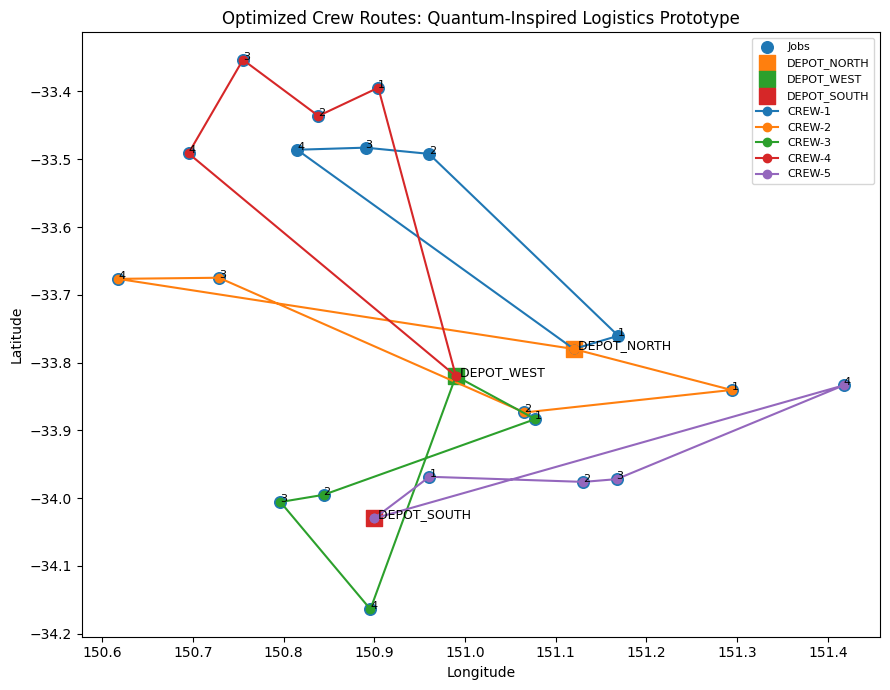

In [20]:
# ============================================================
# 20. Optimized route visualisation
# ============================================================

plt.figure(figsize=(9, 7))

# Plot all selected jobs.
plt.scatter(jobs["site_lon"], jobs["site_lat"], s=70, label="Jobs")

# Plot depots.
for depot_id, (lat, lon) in depots.items():
    plt.scatter(lon, lat, marker="s", s=140, label=depot_id)
    plt.text(lon, lat, f" {depot_id}", fontsize=9)

# Plot routes.
for k, route in enumerate(optimized_routes):
    if not route:
        continue
    vehicle = vehicles.loc[k]
    depot_lat, depot_lon = depots[vehicle["depot_id"]]

    route_lons = [depot_lon] + [jobs.loc[j, "site_lon"] for j in route] + [depot_lon]
    route_lats = [depot_lat] + [jobs.loc[j, "site_lat"] for j in route] + [depot_lat]

    plt.plot(route_lons, route_lats, marker="o", label=vehicle["vehicle_id"])

    for seq, job_idx in enumerate(route, start=1):
        plt.text(jobs.loc[job_idx, "site_lon"], jobs.loc[job_idx, "site_lat"], str(seq), fontsize=8)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Optimized Crew Routes: Quantum-Inspired Logistics Prototype")
plt.legend(loc="best", fontsize=8)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "qilo_optimized_routes.png", dpi=150, bbox_inches="tight")
plt.show()

In [21]:
# ============================================================
# 21. Final optimized schedule
# ============================================================

def hour_to_clock(hour_value):
    hour_value = float(hour_value)
    hours = int(hour_value)
    minutes = int(round((hour_value - hours) * 60))
    if minutes == 60:
        hours += 1
        minutes = 0
    return f"{hours:02d}:{minutes:02d}"

schedule_export = optimized_schedule.copy()
for col in ["arrival_hr", "service_start_hr", "service_finish_hr"]:
    schedule_export[col.replace("_hr", "_time")] = schedule_export[col].apply(hour_to_clock)

schedule_export = schedule_export.sort_values(["vehicle_id", "sequence"]).reset_index(drop=True)

print("Optimized schedule preview:")
display(schedule_export[[
    "vehicle_id", "sequence", "job_id", "inverter_id", "priority_score", "required_part_type",
    "skill_required", "arrival_time", "service_start_time", "service_finish_time", "lateness_hr"
]])

schedule_export.to_csv(OUTPUT_DIR / "optimized_crew_schedule.csv", index=False)

Optimized schedule preview:


,vehicle_id,sequence,job_id,inverter_id,priority_score,required_part_type,skill_required,arrival_time,service_start_time,service_finish_time,lateness_hr
0,CREW-1,1,JOB-011,INV-0005,79.559376,Power_Quality_Module,Electrical,08:05,08:05,10:01,0.000000
1,CREW-1,2,JOB-013,INV-0089,78.450987,Cooling_Fan_Kit,General,10:40,10:40,12:44,0.000000
2,CREW-1,3,JOB-002,INV-0059,87.790907,Power_Quality_Module,Electrical,12:51,12:51,14:56,0.856812
3,CREW-1,4,JOB-014,INV-0084,78.375207,Power_Quality_Module,Electrical,15:04,15:04,16:59,3.059251
4,CREW-2,1,JOB-015,INV-0014,77.668167,Cooling_Fan_Kit,General,08:19,08:19,10:10,0.000000
5,CREW-2,2,JOB-001,INV-0006,89.649411,Cooling_Fan_Kit,General,10:33,10:33,12:38,0.000000
6,CREW-2,3,JOB-005,INV-0012,85.572616,Cooling_Fan_Kit,General,13:19,13:19,15:24,1.324604
7,CREW-2,4,JOB-009,INV-0029,82.676143,Capacitor_Pack,General,15:35,15:35,17:40,3.586967
8,CREW-3,1,JOB-003,INV-0086,87.120369,Power_Quality_Module,Electrical,08:12,08:12,10:16,0.000000
9,CREW-3,2,JOB-004,INV-0037,85.764052,Power_Quality_Module,Electrical,10:43,10:43,12:48,0.000000


## 8. Multi-depot spare-parts planning

The PRD also requires multi-depot inventory routing capability. The prototype below converts scheduled jobs into part demand and creates a simple reorder recommendation.

This is not a full stochastic inventory model yet. It is a transparent first version that can later be upgraded with:

- lead time uncertainty,
- supplier reliability,
- holding cost,
- stockout cost,
- minimum order quantities,
- warehouse capacity,
- multi-period demand forecasts.

In [22]:
# ============================================================
# 22. Spare-parts demand and reorder plan
# ============================================================

part_demand = (
    jobs.groupby("required_part_type")
    .agg(
        scheduled_demand_units=("required_part_type", "size"),
        total_weight_kg=("part_weight_kg", "sum"),
        avg_priority=("priority_score", "mean"),
    )
    .reset_index()
)
part_demand["safety_stock_units"] = np.ceil(part_demand["scheduled_demand_units"] * 0.25).astype(int)
part_demand["required_units_with_buffer"] = part_demand["scheduled_demand_units"] + part_demand["safety_stock_units"]

print("Fleet-level part demand:")
display(part_demand)

# Synthetic current depot inventory.
# Replace this table with ERP inventory data in production.
rng_inventory = random.Random(RANDOM_STATE)
inventory_rows = []
for depot_id in depots.keys():
    for part_type in part_weight.keys():
        inventory_rows.append({
            "depot_id": depot_id,
            "required_part_type": part_type,
            "current_stock_units": rng_inventory.randint(1, 7),
        })

inventory_df = pd.DataFrame(inventory_rows)

reorder_plan = inventory_df.merge(
    part_demand[["required_part_type", "scheduled_demand_units"]],
    on="required_part_type",
    how="left",
).fillna({"scheduled_demand_units": 0})

reorder_plan["minimum_buffer_units"] = np.ceil(reorder_plan["scheduled_demand_units"] / len(depots) * 0.25).astype(int)
reorder_plan["target_stock_units"] = np.ceil(
    reorder_plan["scheduled_demand_units"] / len(depots) + reorder_plan["minimum_buffer_units"]
).astype(int)
reorder_plan["reorder_qty"] = np.maximum(
    0,
    reorder_plan["target_stock_units"] - reorder_plan["current_stock_units"],
).astype(int)

print("Depot reorder plan:")
display(reorder_plan.sort_values(["depot_id", "reorder_qty"], ascending=[True, False]))

part_demand.to_csv(OUTPUT_DIR / "fleet_level_part_demand.csv", index=False)
reorder_plan.to_csv(OUTPUT_DIR / "depot_reorder_plan.csv", index=False)

Fleet-level part demand:


,required_part_type,scheduled_demand_units,total_weight_kg,avg_priority,safety_stock_units,required_units_with_buffer
0,Capacitor_Pack,4,180,81.581906,1,5
1,Control_Board,2,16,80.666299,1,3
2,Cooling_Fan_Kit,8,144,80.241788,2,10
3,Power_Quality_Module,6,180,82.696688,2,8


Depot reorder plan:


,depot_id,required_part_type,current_stock_units,scheduled_demand_units,minimum_buffer_units,target_stock_units,reorder_qty
1,DEPOT_NORTH,Power_Quality_Module,1,6.0,1,3,2
2,DEPOT_NORTH,Capacitor_Pack,1,4.0,1,3,2
0,DEPOT_NORTH,Cooling_Fan_Kit,6,8.0,1,4,0
3,DEPOT_NORTH,Insulation_Test_Kit,6,0.0,0,0,0
4,DEPOT_NORTH,Control_Board,3,2.0,1,2,0
5,DEPOT_NORTH,General_Service_Kit,2,0.0,0,0,0
13,DEPOT_SOUTH,Power_Quality_Module,1,6.0,1,3,2
16,DEPOT_SOUTH,Control_Board,1,2.0,1,2,1
12,DEPOT_SOUTH,Cooling_Fan_Kit,5,8.0,1,4,0
14,DEPOT_SOUTH,Capacitor_Pack,5,4.0,1,3,0


In [23]:
# ============================================================
# 23. Business impact summary
# ============================================================

improvement_pct = 100 * (baseline_kpis["objective"] - optimized_kpis["objective"]) / baseline_kpis["objective"]
distance_reduction_pct = 100 * (baseline_kpis["total_distance_km"] - optimized_kpis["total_distance_km"]) / baseline_kpis["total_distance_km"]
lateness_reduction_pct = 100 * (baseline_kpis["total_lateness_hr"] - optimized_kpis["total_lateness_hr"]) / max(baseline_kpis["total_lateness_hr"], 1e-9)

evaluation_summary = pd.DataFrame({
    "Metric": [
        "Failure-risk model ROC-AUC",
        "Failure-risk model average precision",
        "Optimization objective improvement",
        "Route distance reduction",
        "Lateness reduction",
        "Optimized total distance km",
        "Optimized total overtime hours",
        "Capacity violation kg",
        "Skill violations",
    ],
    "Value": [
        round(roc_auc, 4),
        round(avg_precision, 4),
        f"{improvement_pct:.2f}%",
        f"{distance_reduction_pct:.2f}%",
        f"{lateness_reduction_pct:.2f}%",
        round(optimized_kpis["total_distance_km"], 2),
        round(optimized_kpis["total_overtime_hr"], 2),
        round(optimized_kpis["capacity_violation_kg"], 2),
        int(optimized_kpis["skill_violations"]),
    ]
})

display(evaluation_summary)
evaluation_summary.to_csv(OUTPUT_DIR / "prototype_evaluation_summary.csv", index=False)

print("Prototype outputs saved to:", OUTPUT_DIR)
print("Generated files:")
for file in sorted(OUTPUT_DIR.glob("*")):
    print("-", file.name)

,Metric,Value
0,Failure-risk model ROC-AUC,0.9981
1,Failure-risk model average precision,0.9263
2,Optimization objective improvement,13.62%
3,Route distance reduction,22.12%
4,Lateness reduction,27.91%
5,Optimized total distance km,569.44
6,Optimized total overtime hours,0.86
7,Capacity violation kg,0.0
8,Skill violations,0


Prototype outputs saved to: /mnt/data/prototype_outputs
Generated files:
- depot_reorder_plan.csv
- fleet_level_part_demand.csv
- optimized_crew_schedule.csv
- prototype_evaluation_summary.csv
- qilo_optimized_routes.png
- qilo_simulated_annealing_convergence.png
- routing_kpi_comparison.csv
- selected_logistics_jobs.csv


## 9. Prototype interpretation

This prototype demonstrates an end-to-end path from inverter health data to logistics decisions:

1. **Predictive signal:** The failure-risk model estimates which assets are likely to fail within 7 days.
2. **Job generation:** High-risk inverters are converted into maintenance jobs with priority, part type, skill requirement, and time windows.
3. **Baseline routing:** A greedy plan provides a realistic manual-style benchmark.
4. **Quantum-inspired optimization:** Simulated annealing searches across job swaps, relocations, and route reversals to reduce the multi-objective logistics cost.
5. **Inventory routing support:** Scheduled jobs are translated into part demand and depot reorder recommendations.

## Production upgrade path

For the next version, replace the synthetic logistics assumptions with real operational data:

- real site latitude and longitude,
- technician home/depot location,
- real vehicle capacity,
- real travel-time API or distance matrix,
- real CMMS job duration,
- ERP stock levels,
- supplier lead times,
- operator-approved business constraints.

After that, the optimizer can be upgraded from simulated annealing to a hybrid solver using Qiskit, D-Wave Ocean, OR-Tools, or a commercial vehicle-routing solver with quantum-inspired warm starts.